
we try to solve some DE for CSTR reactor. The first example is given by:
\begin{align}
    \frac{dC_A}{dt}&=\frac{Q}{V}(C_{A,0}-C_A)+r_A\\
    mc_p\frac{dT}{dt}&=mc_p(T_0-T)-\sum_i r_i (\Delta_r H_i) + q_i\\
\end{align}

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


In [3]:

# Parameters
Q = 10.0
V = 100.0

CAin = 2.0
Tin = 300.0

k0 = 1e7
E = 50000.0
R = 8.314

dH = -80000.0

m = 100.0
Cp = 4000.0

qdot = 0.0

def reactor(t, y):

    CA, T = y

    k = k0*np.exp(-E/(R*T))

    rA = -k*CA

    dCAdt = (Q/V)*(CAin - CA) + rA

    dTdt = (
        Q*Cp*(Tin - T)
        - V*rA*dH
        + qdot
    )/(m*Cp)

    return [dCAdt, dTdt]

sol = solve_ivp(
    reactor,
    [0,100],
    [2.0,300],
    dense_output=True
)

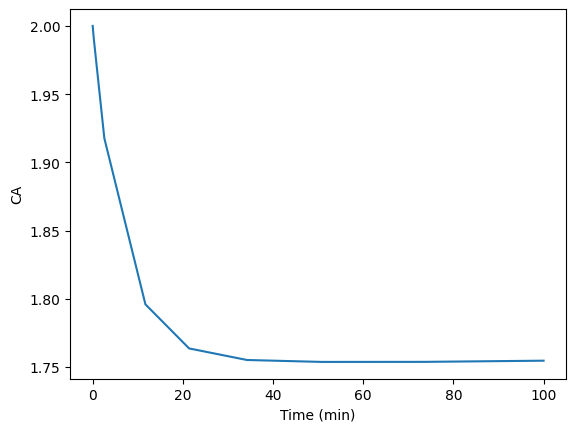

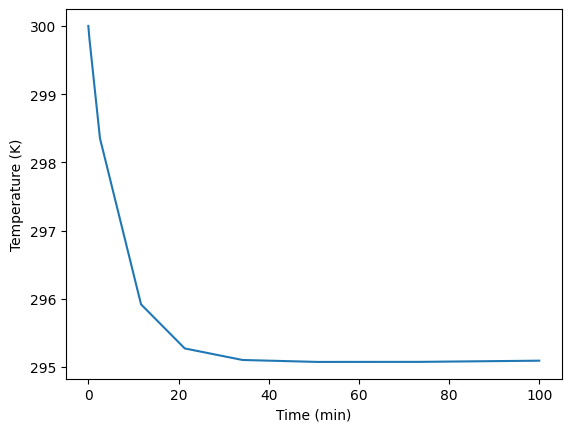

In [4]:
plt.plot(sol.t, sol.y[0])
plt.xlabel("Time (min)")
plt.ylabel("CA")
plt.show()
plt.plot(sol.t, sol.y[1])
plt.xlabel("Time (min)")
plt.ylabel("Temperature (K)")
plt.show()

In [5]:
feed_temps=[310,350,400,450,500,600,1000]
for Tin in feed_temps:
    sol=solve_ivp(
        reactor,
        [0,100],
        [2.0,300])
    final_temp=sol.y[1,-1]
    print(Tin, final_temp)

310 302.4771339412999
350 328.73834904418516
400 365.0074654584271
450 410.8824085229433
500 460.1796428196385
600 560.0048336737487
1000 959.968434734724


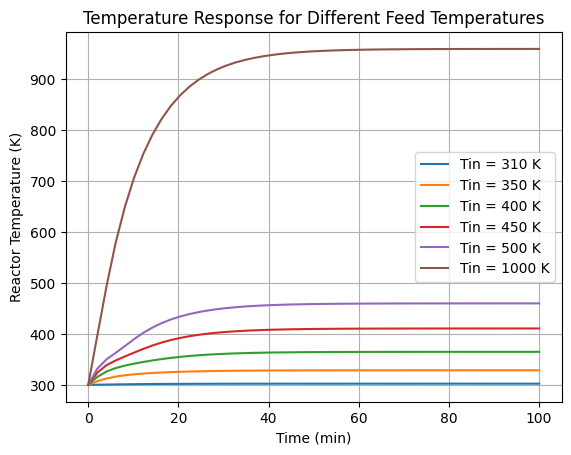

CPU times: total: 37.4 s
Wall time: 37.7 s


In [13]:
%%time
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

Tin_values = [310,350,400,450,500,1000]

t_eval = np.linspace(0, 100, 50)

for Tin in Tin_values:

    def reactor(t, y):

        CA, T = y

        k = k0*np.exp(-E/(R*T))
        rA = -k*CA

        dCAdt = (Q/V)*(CAin - CA) + rA

        dTdt = (
            Q*Cp*(Tin - T)
            - V*rA*dH
            + qdot
        )/(m*Cp)

        return [dCAdt, dTdt]

    sol = solve_ivp(
        reactor,
        [0, 100],
        [2.0, 300],
        t_eval=t_eval
    )

    plt.plot(
        sol.t,
        sol.y[1],
        label=f"Tin = {Tin} K"
    )

plt.xlabel("Time (min)")
plt.ylabel("Reactor Temperature (K)")
plt.title("Temperature Response for Different Feed Temperatures")
plt.legend()
plt.grid(True)
plt.show()